# LLM Evals: a hands-on course

*Lecture notebook. Read the markdown like lecture notes, run the code like a lab. Everything runs offline on simulated data.*

## Why evals?
You cannot improve what you cannot measure, and LLM systems fail in ways nobody predicted. Evals turn "it feels better" into evidence.
They are also how you know whether a prompt change, a new model, or a harness tweak (see the Harness course) actually helped.

## Learning objectives
1. Run **error analysis**: read real outputs, name the failure modes, count them, and fix the biggest first.
2. Choose between **code-based graders** and **LLM judges**, and know when each is valid.
3. **Validate a judge** against human labels (TPR, TNR, kappa) before trusting it.
4. **Correct** a biased judge's pass rate, and know its limits.
5. Put **error bars** on every number, and tell signal from noise when comparing two systems.
6. Build a **regression suite** and know the traps (contamination, overfitting the eval).

## The core loop
```
   collect real traces  -->  READ them (error analysis)  -->  name failure modes
          ^                                                         |
          |                                                         v
   ship + monitor  <--  fix the biggest failure  <--  write a targeted grader per failure
          |                                                         |
          +--------------  measure with error bars  <--------------+
```
**The principle to remember:** start from the failures you *observe*, not the ones you imagine. Teams that do this well
reportedly spend most of their development time on error analysis and evaluation, not on prompts.

## How to use this notebook
- Companion code: `evals.py` (graders, simulated judge, bootstrap, kappa, bias correction).
- All data is **synthetic** with known ground truth, so you can check whether your measurement method recovers the truth.
  Real life never gives you that luxury, which is exactly why we practice here first.
- **Slide deck** for this course: https://claude.ai/artifact/Rvbz1Na7RMnTUU8ZBRGmx8 (private to your Claude account)

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from collections import Counter
from evals import *     # exact_match, regex_match, valid_json_with, bootstrap_ci, cohen_kappa, tpr_tnr, corrected_pass_rate, SimulatedJudge, make_dataset, FAILURE_MODES

## 1. Error analysis: the highest-leverage habit

**Concept.** Before writing any metric, **read outputs**. A practical recipe:

1. **Sample** 50 to 100 real traces (inputs, retrieved context, outputs). Not synthetic prompts, real ones.
2. **Open coding:** next to each bad output, write a free-text note about what went wrong. No categories yet.
3. **Axial coding:** cluster the notes into a handful of **failure modes**.
4. **Count** them. Failure distributions are lopsided: a few modes cause most failures (the Pareto principle).
5. Fix or write a grader for the **biggest** mode first. Repeat.

Here our synthetic dataset already has a failure label per bad output. In practice *you* create these labels by reading.

In [ ]:
data = make_dataset(n=200, seed=7, true_pass_rate=0.70)
df = pd.DataFrame(data)
print("true pass rate (hidden ground truth):", round(df["good"].mean(), 3))
print("\nA few examples of failed outputs:")
df[~df["good"]][["id", "failure"]].head(5)

In [ ]:
# Pareto chart: failure modes sorted by frequency, with the cumulative share.
counts = df["failure"].value_counts()
cum = counts.cumsum() / counts.sum()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(counts.index, counts.values, color="tab:blue")
ax.set_ylabel("number of failures"); ax.tick_params(axis="x", rotation=25)
ax2 = ax.twinx(); ax2.plot(counts.index, cum.values, color="tab:orange", marker="o"); ax2.set_ylim(0, 1.05)
ax2.set_ylabel("cumulative share")
ax.set_title("Failure modes: a few dominate (fix the left bars first)")
plt.tight_layout(); plt.show()

print(f"Top 2 modes account for {cum.iloc[1]:.0%} of all failures: {list(counts.index[:2])}")

**Checkpoint 1.**
1. Why is "fix the top failure mode" a better strategy than "improve overall quality"?
2. Our top mode is `hallucinated_policy`. What *grader* could detect it automatically? (Think: compare claims to a policy document.)
3. Why must the traces be *real* user traffic and not prompts you wrote yourself?

## 2. Code-based graders: cheap, fast, deterministic

**Concept.** If a property can be checked by **code**, check it with code. Code graders are free, instant, reproducible and have no bias.

| Grader | Checks | Example |
|---|---|---|
| Exact / normalized match | closed-form answers | the answer equals `"42"` |
| Regex / keyword | required or forbidden phrases | must mention "30 days"; must not contain a competitor name |
| Format / schema | structured output | valid JSON with keys `intent`, `confidence` |
| Execution | code or SQL outputs | run the generated SQL, compare result rows |
| Tool-call check | agent actions | called `refund` with the right order id |

Their limit: they cannot judge meaning, tone or helpfulness. That is where judges come in (section 3).

In [ ]:
cases = [
    ("exact_match",     lambda: exact_match("  Paris ", "paris")),
    ("regex_match",     lambda: regex_match("Refunds are allowed within 30 days.", r"\b30 days\b")),
    ("json ok",         lambda: valid_json_with('{"intent": "refund", "confidence": 0.9}', ["intent", "confidence"])),
    ("json missing key", lambda: valid_json_with('{"intent": "refund"}', ["intent", "confidence"])),
    ("json malformed",  lambda: valid_json_with("{intent: refund}", ["intent"])),
]
pd.DataFrame([{"grader": n, "passes": f()} for n, f in cases])

## 3. LLM-as-judge: powerful, but it is a measuring instrument that needs calibrating

**Concept.** For fuzzy criteria (faithful? polite? helpful?), a second LLM grades the output. This scales human judgment but **adds noise and bias**.

**Design rules that make judges more reliable**
- **One failure mode per judge**, written as a **binary pass/fail** with a precise definition. Avoid vague 1 to 10 scores: they drift and are hard to validate.
- Give the judge the **evidence** it needs (the source document, the policy), not just the answer.
- Ask for a **short reason first**, then the verdict.
- Use **few-shot examples** drawn from your own labeled failures.

**Known biases:** *verbosity* (longer looks better), *position* (prefers the first option in a pairwise comparison), *self-preference* (favors its own model family's style).

**The non-negotiable step: validate the judge against human labels.** A judge is a classifier. Measure it like one.

Our `SimulatedJudge` has *known* error rates, so we can check that our measurement recovers them.

In [ ]:
human = df["good"].to_numpy()                                    # here the "human label" is the ground truth
judge = SimulatedJudge(tpr=0.92, tnr=0.55, seed=1).judge(data)   # a plausible, somewhat lenient judge

tpr, tnr = tpr_tnr(judge, human)
print(f"TPR (passes truly good outputs): {tpr:.2f}")
print(f"TNR (fails truly bad outputs)  : {tnr:.2f}")
print(f"Cohen's kappa vs human         : {cohen_kappa(judge, human):.2f}")
print(f"\nraw judge pass rate: {judge.mean():.3f}   true pass rate: {human.mean():.3f}")

In [ ]:
# Confusion matrix as a picture. Off-diagonal cells are where the judge is wrong.
cm = np.array([[(~judge & ~human).sum(), (judge & ~human).sum()],
               [(~judge &  human).sum(), (judge &  human).sum()]])
fig, ax = plt.subplots(figsize=(4.6, 4))
ax.imshow(cm, cmap="Blues")
for i in range(2):
    for j in range(2):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=16, color="white" if cm[i, j] > cm.max() / 2 else "black")
ax.set_xticks([0, 1]); ax.set_xticklabels(["judge: FAIL", "judge: PASS"])
ax.set_yticks([0, 1]); ax.set_yticklabels(["human: BAD", "human: GOOD"])
ax.set_title("Judge versus human"); plt.show()

**Reading the result.** The judge is good at passing good outputs (high TPR, True Positive Rate) but **too lenient on bad ones** (low TNR, True Negative Rate): it lets many bad outputs through.
So its raw pass rate **overestimates quality**. A dashboard built on this judge would look healthier than reality.

### What is "Cohen's kappa vs human"?
The printed line `Cohen's kappa vs human` is one number that answers: **how much does the judge agree with the human, beyond what random luck would give?**
"vs human" just means the two raters being compared are the judge and the human labels (here, the ground truth).

**Why not just use plain agreement?** Two raters can agree a lot by accident. If 90% of outputs are good and a judge says PASS to everything, it agrees with the human 90% of the time while knowing nothing.
Kappa subtracts out that "agreement by luck", so a useless judge scores about 0.

**Formula**

`kappa = (po - pe) / (1 - pe)`

- `po` (observed agreement) = share of outputs where judge and human gave the same verdict.
- `pe` (expected agreement by chance) = agreement you would get if both raters guessed independently, using their own pass rates:
  `pe = (judge pass rate x human pass rate) + (judge fail rate x human fail rate)`

**Worked example** (100 outputs). Humans pass 70%. The judge passes 85%. They agree on 80 outputs.
- `po = 0.80`
- `pe = 0.85 x 0.70 + 0.15 x 0.30 = 0.595 + 0.045 = 0.64`
- `kappa = (0.80 - 0.64) / (1 - 0.64) = 0.16 / 0.36 = 0.44`  (moderate)

An 80% agreement sounds good, but kappa shows that much of it was luck.

**Reading the number**

| kappa | Meaning |
|---|---|
| 1 | perfect agreement |
| 0 | no better than chance (for example, "always PASS") |
| below 0 | worse than chance (the judge disagrees systematically) |

Rough guide: below 0.4 weak, 0.4 to 0.6 moderate, 0.6 to 0.8 good, above 0.8 strong.

**Kappa vs TPR and TNR.** Kappa is a single summary score. TPR and TNR tell you *which way* the judge is wrong (too lenient or too harsh). Report all three: kappa to see overall quality, TPR and TNR to see the kind of mistake.

**Checkpoint 2.**
1. If most outputs are good, why can accuracy look high even for a useless judge? (Use kappa, TPR and TNR instead.)
2. Which error is more dangerous for a safety eval: low TPR or low TNR?
<br> -> low TNR

## 4. Correcting a biased judge

### The problem, in one picture
Section 3 showed that our lenient judge passes **77%** of outputs, but the true pass rate is **70%**. The judge is like a scale that always reads a bit heavy.
If you know *how* it is off, you can subtract the error and recover a better estimate of the real number. That is what this section does.

### A few terms first
| Term | Plain meaning |
|---|---|
| **Pass rate** | the share of outputs that pass, for example 0.70 means 70% |
| **True pass rate** (`p`) | the pass rate if a perfect human graded everything. Unknown in real life. |
| **Observed pass rate** | the pass rate the judge reports. This is what we can see, but it is biased. |
| **Calibration set** | a small sample that a human labels by hand, so we can measure how the judge errs |
| **TPR (True Positive Rate)** | good outputs the judge passed / all truly good outputs |
| **TNR (True Negative Rate)** | bad outputs the judge failed / all truly bad outputs |

### Where the formula comes from (no magic)
The judge's passes come from two sources:
1. **Good outputs it correctly passes.** A share `p` of outputs are good, and the judge passes a fraction TPR of them: `TPR x p`.
2. **Bad outputs it wrongly passes.** A share `1 - p` are bad, and the judge wrongly passes a fraction `1 - TNR` of them: `(1 - TNR) x (1 - p)`.

Add the two sources and you get what the judge reports:

$$\text{observed} = \text{TPR}\cdot p + (1-\text{TNR})\cdot(1-p)$$

We can see `observed`, and we can measure TPR and TNR on the calibration set. The only unknown is `p`, so we solve for it with a little algebra:

$$\Rightarrow\quad p=\frac{\text{observed}+\text{TNR}-1}{\text{TPR}+\text{TNR}-1}$$

(This is the Rogan-Gladen estimator.) An estimator is just a recipe for guessing an unknown number from data.

### Worked example with real numbers
Suppose the judge reports `observed = 0.77`. On the calibration set we measure `TPR = 0.88` and `TNR = 0.53`.

- Top of the fraction: `0.77 + 0.53 - 1 = 0.30`
- Bottom of the fraction: `0.88 + 0.53 - 1 = 0.41`
- `p = 0.30 / 0.41 = 0.73`

The raw judge said 0.77, the corrected answer is 0.73, and the truth is 0.70. The correction moved us most of the way there.

### The practical workflow
1. **Label a small set by hand** (say 60 outputs). This is the calibration set.
2. **Measure TPR and TNR** of the judge on that set.
3. **Run the cheap judge on everything** and note its observed pass rate.
4. **Apply the formula** to get the corrected pass rate.

Note this fixes the **aggregate** only (the overall percentage). It does not fix individual wrong verdicts: the judge is still wrong on the same outputs as before.


true pass rate      : 0.650
raw judge estimate  : 0.760   (biased upward)
corrected estimate  : 0.632   95% CI [0.187, 0.864]


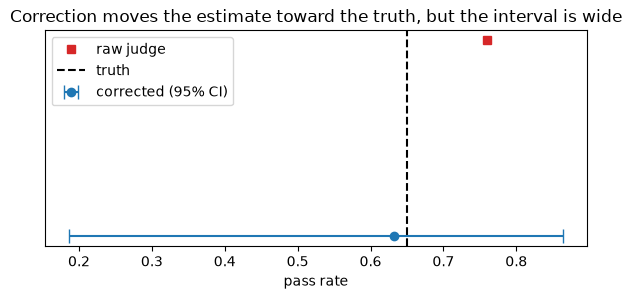

In [10]:
rng = np.random.default_rng(0)
cal_idx = rng.choice(len(data), size=60, replace=False)      # the 60 outputs a human actually labeled

def corrected_estimate(cal_idx, all_idx):
    tpr_c, tnr_c = tpr_tnr(judge[cal_idx], human[cal_idx])    # judge quality from the calibration set
    return corrected_pass_rate(judge[all_idx].mean(), tpr_c, tnr_c)

all_idx = np.arange(len(data))
point = corrected_estimate(cal_idx, all_idx)

# Bootstrap the WHOLE procedure (resample both the calibration set and the full set) for an honest interval.
boots = [corrected_estimate(rng.choice(cal_idx, 60), rng.choice(all_idx, len(all_idx))) for _ in range(2000)]
boots = [b for b in boots if not np.isnan(b)]
lo, hi = np.quantile(boots, [0.025, 0.975])

print(f"true pass rate      : {human.mean():.3f}")
print(f"raw judge estimate  : {judge.mean():.3f}   (biased upward)")
print(f"corrected estimate  : {point:.3f}   95% CI [{lo:.3f}, {hi:.3f}]")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.errorbar([point], [0], xerr=[[point - lo], [hi - point]], fmt="o", capsize=5, label="corrected (95% CI)")
ax.plot([judge.mean()], [0.25], "s", color="tab:red", label="raw judge")
ax.axvline(human.mean(), color="k", ls="--", label="truth")
ax.set_yticks([]); ax.set_xlabel("pass rate"); ax.legend(loc="upper left"); ax.set_title("Correction moves the estimate toward the truth, but the interval is wide"); plt.show()

### How to read the output of the code above

The cell prints three numbers. Here is what each one means.

**Raw judge estimate (77%).** Just the judge's pass rate, uncorrected. It is too high because the judge is lenient.

**Corrected estimate (a point estimate).** A **point estimate** is a *single best guess* for an unknown number. Ours is about 0.72, close to the truth of 0.70.
But a single guess hides how sure we are. If we had picked a different 60 outputs to label, we would have got a different guess.

**95% CI (Confidence Interval).** An interval gives a *range* of believable values instead of one number. Read "95% CI [0.22, 1.00]" as:
"if we repeated this whole procedure many times, about 95% of the ranges built this way would contain the true value."
A narrow interval means a precise estimate. A wide one means "we do not really know".

Our interval runs from about 0.22 to 1.00. That is nearly the whole scale, so **the point estimate looks good but we cannot actually trust it**.
(The top is stuck at 1.00 because the function clips answers to the range 0 to 1.)

### How the interval is built: the bootstrap
The **bootstrap** is a way to see how much your answer would wobble from sample to sample, without collecting new data.
1. Take your labeled examples and **draw new samples from them, with replacement** (the same example can be picked twice).
2. Recompute the corrected estimate on each new sample.
3. Repeat 2000 times, giving 2000 slightly different estimates.
4. Take the middle 95% of them. The 2.5th and 97.5th percentiles are the ends of the interval.

The code resamples **both** the calibration set and the full set, because both are samples and both add uncertainty.

### Why is the interval so wide?
Two reasons stack up.

**1. TNR is measured from very few examples.** Only about 17 of the 60 calibration outputs are bad, so TNR is estimated from about 17 cases.
With that few, TNR could easily be off by roughly 0.2 either way.

**2. The correction magnifies that error.** Look at the bottom of the fraction, `TPR + TNR - 1`. For our judge it is only about 0.41.
Dividing by a small number blows up any mistake. Try TNR = 0.40 instead of 0.53 in the worked example:
`(0.77 + 0.40 - 1) / (0.88 + 0.40 - 1) = 0.17 / 0.28 = 0.61`, down from 0.73. A modest change in TNR moved the answer by 12 points.

If TPR + TNR is close to 1, the judge is barely better than a coin flip, and the correction becomes extremely unstable. If it is exactly 1 or less, the formula breaks (the code returns `nan`, "not a number").

**The fix: a bigger calibration set, especially of the rarer class** (here the bad outputs). The next cell shows how fast the interval shrinks.


In [ ]:
# How many human labels do we need? Repeat the correction with different calibration sizes.
results = []
for size in [30, 60, 120, 200]:
    r = np.random.default_rng(size)
    idx = r.choice(len(data), size=size, replace=False)
    bs = [corrected_estimate(r.choice(idx, size), r.choice(all_idx, len(all_idx))) for _ in range(1500)]
    bs = [b for b in bs if not np.isnan(b)]
    l, h = np.quantile(bs, [0.025, 0.975])
    est = corrected_estimate(idx, all_idx)
    results.append({"size": size, "estimate": est, "lo": l, "hi": h, "width": h - l})
    print(f"calibration labels={size:4d}  estimate={est:.3f}  95% CI [{l:.3f}, {h:.3f}]  width={h - l:.2f}")

# Plot: each dot is the point estimate, the bar is its 95% CI (Confidence Interval). The dashed line is the truth.
res = pd.DataFrame(results)
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar(range(len(res)), res["estimate"],
            yerr=[res["estimate"] - res["lo"], res["hi"] - res["estimate"]],
            fmt="o", capsize=5, label="corrected estimate (95% CI)")
ax.axhline(human.mean(), color="k", ls="--", label="true pass rate")
ax.axhline(judge.mean(), color="tab:red", ls=":", label="raw judge (biased)")
ax.set_xticks(range(len(res))); ax.set_xticklabels(res["size"])
ax.set_xlabel("number of human-labeled calibration examples"); ax.set_ylabel("estimated pass rate")
ax.set_ylim(0, 1.05); ax.set_title("More labels: the interval narrows (the point estimate just stops wobbling)")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

**What to expect from the table above.** When I ran it, the interval width was about 1.00 (30 labels), 0.96 (60), 0.33 (120) and 0.33 (200).
Notice the **point estimate jumped around** (about 0.68, 0.63, 0.75, 0.70) even though the truth never changed. That is noise from small samples, and it is exactly why a point estimate alone is not enough.

**Caveats (important).** The correction only works if two assumptions hold:
1. **The calibration set is representative.** If you labeled only easy cases, the TPR and TNR you measure will not match the judge's behavior on real traffic.
2. **The judge's error rates are the same everywhere.** If the judge is harsher on some topics than others, one pair of TPR and TNR cannot describe it.

If either fails, the corrected number can be confidently wrong. Re-validate whenever you change the judge prompt or model.

**Verbosity bias demo.** Now the judge also tends to pass long answers. Our `too_verbose` failures are exactly the long ones, so this judge will miss them.


In [12]:
fair = SimulatedJudge(tpr=0.92, tnr=0.75, verbosity_bias=0.0, seed=2).judge(data)
biased = SimulatedJudge(tpr=0.92, tnr=0.75, verbosity_bias=0.5, seed=2).judge(data)

verbose_rows = df["failure"] == "too_verbose"
print("Catch rate on 'too_verbose' failures (higher is better):")
print(f"  judge without verbosity bias: {(~fair[verbose_rows]).mean():.0%}")
print(f"  judge with verbosity bias   : {(~biased[verbose_rows]).mean():.0%}")

Catch rate on 'too_verbose' failures (higher is better):
  judge without verbosity bias: 100%
  judge with verbosity bias   : 20%


**Checkpoint 3.** The biased judge looks fine overall but is blind to one failure mode. Which analysis from section 1 would have caught this
(hint: compute judge accuracy *per failure mode*, not just overall)?

## 5. Statistics: put error bars on everything

**Concept.** An eval score is an *estimate* from a finite sample. "System B scores 74%, A scores 71%" means nothing without uncertainty.
The **bootstrap** is the easiest honest tool: resample your results with replacement many times, recompute the metric, and read off the spread.

Rules of thumb:
- Uncertainty shrinks like **1 / sqrt(n)**. Halving the error bar needs **4x** the examples.
- For comparing two systems on the **same** examples, bootstrap the **paired difference**.
- Report the **interval**, not just the mean.

In [ ]:
true_p = 0.70
sizes = [20, 50, 100, 200, 500, 1000, 2000]
rows = []
for n in sizes:
    sample = np.random.default_rng(n).random(n) < true_p            # one eval run of size n
    mean, lo, hi = bootstrap_ci(sample)
    rows.append({"n": n, "mean": mean, "lo": lo, "hi": hi, "width": hi - lo})
ci = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.errorbar(range(len(sizes)), ci["mean"], yerr=[ci["mean"] - ci["lo"], ci["hi"] - ci["mean"]], fmt="o", capsize=4)
ax.axhline(true_p, color="k", ls="--", label="true pass rate")
ax.set_xticks(range(len(sizes))); ax.set_xticklabels(sizes); ax.set_xlabel("number of eval examples"); ax.set_ylabel("measured pass rate")
ax.set_title("95% bootstrap interval vs eval size"); ax.legend(); plt.show()
ci.round(3)

In [ ]:
# Is system B really better than A? A truly beats B by 3 points. Can we tell?
def compare(n, seed=0):
    rng = np.random.default_rng(seed)
    easy = rng.random(n)                                    # a shared "difficulty" per example, so the systems are paired
    a = easy < 0.70
    b = easy < 0.73                                         # B is truly 3 points better on the same examples
    diff = b.astype(float) - a.astype(float)
    m, lo, hi = bootstrap_ci(diff, seed=seed)
    return m, lo, hi

for n in [50, 200, 1000, 5000]:
    m, lo, hi = compare(n)
    verdict = "CLEARLY better" if lo > 0 else "cannot tell"
    print(f"n={n:5d}  diff={m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> {verdict}")

**Lesson 1.** At n = 50 the interval touches zero: you cannot claim an improvement. Many "wins" reported from tiny evals are noise.
If an interval includes zero, you have **not** shown an improvement.

**Lesson 2: pairing is powerful.** Above, both systems are scored on the **same** examples, so the shared difficulty cancels and only the examples where they differ matter.
Now compare the same two systems as if they were scored on **independent** samples:

In [ ]:
# Same 3-point true gap, but unpaired: A and B each evaluated on their own random examples.
def compare_unpaired(n, seed=0, n_boot=3000):
    rng = np.random.default_rng(seed)
    a = rng.random(n) < 0.70
    b = rng.random(n) < 0.73
    diffs = [rng.choice(b, n).mean() - rng.choice(a, n).mean() for _ in range(n_boot)]
    lo, hi = np.quantile(diffs, [0.025, 0.975])
    return b.mean() - a.mean(), lo, hi

for n in [200, 1000, 5000]:
    m, lo, hi = compare_unpaired(n)
    print(f"n={n:5d}  diff={m:+.3f}  95% CI [{lo:+.3f}, {hi:+.3f}]  -> {'CLEARLY better' if lo > 0 else 'cannot tell'}")

**Compare the two tables.** The paired design detects the 3-point gap with a few hundred examples; the unpaired design needs far more.
**Always evaluate competing versions on the same examples** and compare paired differences.

**Checkpoint 4.** You have budget to label 200 more examples. Is it better to add them to the **eval set** or to **calibrate the judge**? (Consider what limits your precision right now.)

## 6. What to evaluate in different systems

| System | What to measure | Typical graders |
|---|---|---|
| **Classification / extraction** | accuracy, per-class precision and recall | exact match, schema |
| **RAG** | retrieval: recall@k, MRR, nDCG. Generation: faithfulness to the context, answer relevance | retrieval metrics (see the Hybrid RAG course) + judge for faithfulness |
| **Agents** | task success, **trajectory** quality (right tools, right order, no loops), steps and cost | final-state checks, tool-call checks, trace judges |
| **Chat / writing** | helpfulness, tone, safety | calibrated judges + human review samples |

**Evaluate components separately.** In RAG, a wrong answer can be a retrieval failure or a generation failure. Measure retrieval and generation independently,
otherwise you cannot tell which to fix.

**Agent evals** (connects to the Harness course): grade the **outcome** (did the tests pass? is the record updated?) rather than the exact path,
and separately track efficiency (steps, tokens). Because agents are stochastic, run each task multiple times and report the pass rate with an interval.

## 7. Operating evals: regression suites, traps, and production

**Regression suite.** Keep a growing set of cases (every bug you fix becomes a test). Run it on every prompt, model or harness change, as CI.
Gate merges on "no significant drop", using intervals, not raw point differences.

**Traps**
| Trap | What happens | Defense |
|---|---|---|
| **Overfitting the eval** | you tune until the eval is perfect, real quality does not move | hold out a **fresh** test split, refresh it with new real traffic |
| **Contamination** | eval examples leak into prompts, few-shot examples or training data | keep eval data separate; version it |
| **Goodhart's law** | optimizing a proxy metric breaks the real goal | pair proxy metrics with periodic human review |
| **Unrepresentative set** | the eval does not look like production | sample from real traffic, stratify by topic and difficulty |
| **Unvalidated judge** | confident numbers from a miscalibrated judge | section 3 and 4, every time you change the judge |

**Online evals and monitoring.** After launch: sample production traces, run cheap graders on all of them and judges on a sample,
track failure-mode rates over time, and feed new failures back into error analysis (the loop at the top of this notebook).

**Red teaming.** Deliberately attack the system (prompt injection, jailbreaks, data exfiltration, edge-case inputs) and add every successful attack to the regression suite.

## 8. Exercises

1. **Per-mode judge accuracy:** compute the biased judge's catch rate for each failure mode, and plot it. Which modes is it blind to?
2. **Judge prompt design:** write (as text) a binary judge rubric for `hallucinated_policy`. What evidence must the judge be given?
3. **Calibration size:** repeat section 4 with calibration sizes 20, 60, 200. How does the corrected estimate's interval change?
4. **Position bias:** simulate a pairwise judge that prefers option A 60% of the time regardless of quality. How would you detect and remove the bias? (Swap positions and average.)
5. **Effect size:** in section 5, change the true gap from 3 points to 1 point and to 10 points. How many examples do you need to detect each, paired?
6. **Regression gate:** write a function that fails CI only when the upper bound of the paired-difference interval is below a threshold such as -0.02.
7. **Your own system:** take 30 real outputs from something you built, do open coding by hand, and build a Pareto chart of your own failure modes.
8. **Connect the courses:** apply recall@k from the Hybrid RAG notebook to a retrieval system, then judge faithfulness of the generated answers.

In [ ]:
# Starter for exercise 6: a CI gate based on a paired bootstrap difference.
def regression_gate(old_pass, new_pass, tolerance=0.02, seed=0):
    diff = np.asarray(new_pass, float) - np.asarray(old_pass, float)
    mean, lo, hi = bootstrap_ci(diff, seed=seed)
    regressed = hi < -tolerance               # we are confident the new version is WORSE by more than the tolerance
    return {"mean_diff": round(mean, 3), "ci": (round(lo, 3), round(hi, 3)), "fail_build": bool(regressed)}

rng = np.random.default_rng(3)
old = rng.random(400) < 0.75
worse = old & (rng.random(400) > 0.10)       # new version loses about 10% of the passes
print(regression_gate(old, worse))
print(regression_gate(old, old))

## 9. Glossary

| Term | Meaning |
|---|---|
| **Eval** | a repeatable measurement of system quality on a set of examples |
| **Error analysis** | reading outputs, naming and counting failure modes |
| **Open / axial coding** | free-text notes, then clustering the notes into categories |
| **Grader** | anything that scores an output: code, a judge, or a human |
| **LLM judge** | an LLM prompted to grade outputs |
| **TPR / TNR** | share of good outputs passed / share of bad outputs failed |
| **Cohen's kappa** | agreement between raters, corrected for chance |
| **Rogan-Gladen correction** | estimating a true rate from a noisy classifier with known TPR/TNR |
| **Bootstrap** | resampling with replacement to estimate uncertainty |
| **Paired comparison** | comparing two systems on the same examples |
| **Regression suite** | accumulating test cases run on every change |
| **Contamination** | eval data leaking into development or training |
| **Goodhart's law** | a measure that becomes a target stops being a good measure |
| **Red teaming** | adversarial testing to find failures |

## 10. Cheat sheet
```
Start        : read 50-100 real traces -> name failure modes -> count -> fix the biggest
Graders      : code first (exact, regex, schema, execution); judges only for fuzzy criteria
Judges       : binary, one failure mode each, give evidence, reason then verdict
Validate     : judge vs human labels -> TPR, TNR, kappa (never trust an unvalidated judge)
Aggregate    : corrected = (observed + TNR - 1) / (TPR + TNR - 1), bootstrap the interval
Compare      : paired bootstrap on the difference; interval includes 0 => no proven change
Size         : error bar ~ 1/sqrt(n); 4x data halves it
Operate      : regression suite in CI, fresh holdout, monitor production, red team
```

## 11. Reading list
- Hamel Husain, LLM Evals: Everything You Need to Know: https://hamel.dev/blog/posts/evals-faq/
- Hamel Husain, Should I practice eval-driven development?: https://hamel.dev/blog/posts/evals-faq/should-i-practice-eval-driven-development.html
- Simon Willison, Your AI product needs evals (summary of Hamel's post): https://simonwillison.net/2024/Mar/31/your-ai-product-needs-evals
- The Pragmatic Engineer, Evals: https://newsletter.pragmaticengineer.com/p/evals
- Related courses in this series: Hybrid RAG (retrieval metrics), Harness Engineering (agent traces).

## 12. My experiments log

| # | Change | Result (with interval) | What I learned |
|---|--------|------------------------|----------------|
| 0 | baseline | | |
| 1 | | | |

## Where next
1. Run `langchain_evals_experiment.ipynb`, the same ideas in LangChain / LangSmith / openevals vocabulary.
2. Apply section 1 to a real system of yours, even with 30 examples.
3. **Tool use and MCP**: the next course, and a source of agent behaviors worth evaluating.
4. Learn an eval library once you understand the mechanics (the concepts here transfer to all of them).